# Lab 10-10 · Op-Amp Application Circuits

Companion to [chapter 10-10](../../chapters/10-10-op-amp-application-circuits.md). Predict first; the `assert` lines check against the answer keys.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lti, step

## Part 1 · CMRR Monte Carlo (guided exercise)

Unity-gain difference amplifier, four 10 kΩ resistors with errors uniform within ±0.1%. *Predict first:* the median CMRR.

median 67.92 dB, below 60 dB: 8.22%, lowest 54.52 dB (worst case 53.98 dB)


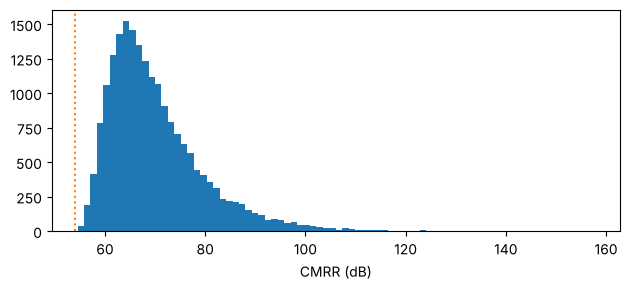

In [2]:
rng = np.random.default_rng(1010)
eps, n = 1e-3, 20000
e = rng.uniform(-eps, eps, (n, 4))
r1, r2, r3, r4 = (1e4 * (1 + e[:, i]) for i in range(4))
a_cm = r4 / (r3 + r4) * (1 + r2 / r1) - r2 / r1
a_d = 0.5 * (r4 / (r3 + r4) * (1 + r2 / r1) + r2 / r1)
cmrr_db = 20 * np.log10(np.abs(a_d / a_cm))
med, below, low = np.median(cmrr_db), np.mean(cmrr_db < 60) * 100, cmrr_db.min()
print(f"median {med:.2f} dB, below 60 dB: {below:.2f}%, lowest {low:.2f} dB (worst case 53.98 dB)")
assert abs(med - 67.9) < 0.05 and abs(below - 8.22) < 5e-3 and abs(low - 54.5) < 0.05
plt.figure(figsize=(6.4, 3.0)); plt.hist(cmrr_db, bins=80); plt.axvline(20 * math.log10(500), color="C1", ls=":")
plt.xlabel("CMRR (dB)"); plt.tight_layout(); plt.show()

## Part 2 · Precision-rectifier error against frequency

Dead time $2V_D/\text{SR}$ = 1.2 V / 6.5 V/µs after each rising crossing; the output's average is compared with the ideal $V_p/\pi$.

In [3]:
from scipy.integrate import quad
dt = 1.2 / 6.5e6
def avg_error(f, vp=1.0):
    # fraction of the half-wave average lost while the output is held at zero for dt after the rising crossing
    w = 2 * np.pi * f
    ideal = quad(lambda t: vp * np.sin(w * t), 0, 1 / (2 * f))[0]
    lost = quad(lambda t: vp * np.sin(w * t), 0, dt)[0]
    return lost / ideal * 100
errs = {f: avg_error(f) for f in (1e3, 1e4, 1e5)}
for f, er in errs.items():
    print(f"{f/1e3:6.0f} kHz: average error {er:.5f}%")
assert abs(errs[1e4] - 0.00336) < 5e-6 and abs(errs[1e5] - 0.336) < 5e-4

     1 kHz: average error 0.00003%
    10 kHz: average error 0.00336%
   100 kHz: average error 0.33601%


## Part 3 · Hysteresis against noise

The noisy ramp of Figure 1 (10 mV rms, seed 1010), thresholds centered on 2.5 V.

In [4]:
rng = np.random.default_rng(1010)
t = np.linspace(0, 1, 4000)
vin = 2.3 + 0.4 * t + rng.normal(0, 0.01, t.size)

def transitions(h):
    state, count = 0, 0
    for x in vin:
        if h == 0:
            new = 1 if x > 2.5 else 0
        elif state == 0:
            new = 1 if x > 2.5 + h / 2 else 0
        else:
            new = 0 if x < 2.5 - h / 2 else 1
        if new != state:
            count += 1
            state = new
    return count

counts = {h: transitions(h) for h in (0.0, 0.02, 0.05, 0.1)}
print(counts)
assert counts[0.0] == 111 and counts[0.02] == 23 and counts[0.05] == 1 and counts[0.1] == 1

{0.0: 111, 0.02: 23, 0.05: 1, 0.1: 1}


## Part 4 · TIA step response against $C_F$

From §3.5, $v_o/i_{pd} = -R_F\omega_t/[R_F(C_{in} + C_F)s^2 + (1 + \omega_tR_FC_F)s + \omega_t]$; the normalized step response is that of $\omega_t/[\ldots]$.

Butterworth C_F = 2.105 pF: 1% settling 1.0545 us


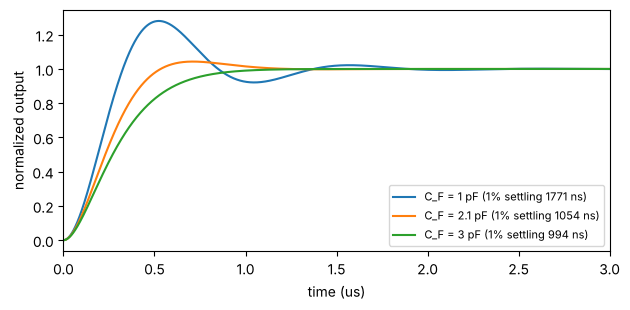

In [5]:
wt, rf, cin = 2 * math.pi * 10e6, 100e3, 14e-12
tt = np.linspace(0, 10e-6, 200001)

def response(cf):
    ct = cin + cf
    _, y = step(lti([wt], [rf * ct, 1 + wt * rf * cf, wt]), T=tt)
    return y

def settle(y, tol=0.01):
    idx = np.where(np.abs(y - 1) > tol)[0][-1]
    return tt[idx + 1]

ts_b = settle(response(2.105e-12))
print(f"Butterworth C_F = 2.105 pF: 1% settling {ts_b*1e6:.4f} us")
assert abs(ts_b * 1e6 - 1.05) < 5e-3
plt.figure(figsize=(6.4, 3.2))
for cf in (1.0e-12, 2.105e-12, 3.0e-12):
    plt.plot(tt * 1e6, response(cf), label=f"C_F = {cf*1e12:.3g} pF (1% settling {settle(response(cf))*1e9:.0f} ns)")
plt.xlim(0, 3); plt.xlabel("time (us)"); plt.ylabel("normalized output"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()